In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
data = pd.read_csv(r"C:\Users\srini\OneDrive\Desktop\Data analytics course\ML\Machine Learning\vehicle_performance.csv")

In [3]:
data.head(4)

,origin,cylinders,displacement,horsepower,weight,acceleration,year,name,Kilometer_per_liter
0,1,8,307.0,130,3504,12.0,1970,chevrolet chevelle malibu,7.652587
1,1,8,350.0,165,3693,11.5,1970,buick skylark 320,6.377156
2,1,8,318.0,150,3436,11.0,1970,plymouth satellite,7.652587
3,1,8,304.0,150,3433,12.0,1970,amc rebel sst,6.802299


In [4]:
data.origin.unique()

array([1, 3, 2], dtype=int64)

In [5]:
data.shape

(398, 9)

In [6]:
data.describe()

,origin,cylinders,displacement,weight,acceleration,year,Kilometer_per_liter
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,1.572864,5.454774,193.425879,2970.424623,15.568090,1976.010050,9.997073
std,0.802055,1.701004,104.269838,846.841774,2.757689,3.697627,3.322917
min,1.000000,3.000000,68.000000,1613.000000,8.000000,1970.000000,3.826293
25%,1.000000,4.000000,104.250000,2223.750000,13.825000,1973.000000,7.440015
50%,1.000000,4.000000,148.500000,2803.500000,15.500000,1976.000000,9.778305
75%,2.000000,8.000000,262.000000,3608.000000,17.175000,1979.000000,12.329168
max,3.000000,8.000000,455.000000,5140.000000,24.800000,1982.000000,19.811697


In [7]:
data.isnull().sum()

origin                 0
cylinders              0
displacement           0
horsepower             0
weight                 0
acceleration           0
year                   0
name                   0
Kilometer_per_liter    0
dtype: int64

In [8]:
data.dtypes

origin                   int64
cylinders                int64
displacement           float64
horsepower              object
weight                   int64
acceleration           float64
year                     int64
name                    object
Kilometer_per_liter    float64
dtype: object

In [9]:
data.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
393    False
394    False
395    False
396    False
397    False
Length: 398, dtype: bool

<Axes: xlabel='Kilometer_per_liter', ylabel='Density'>

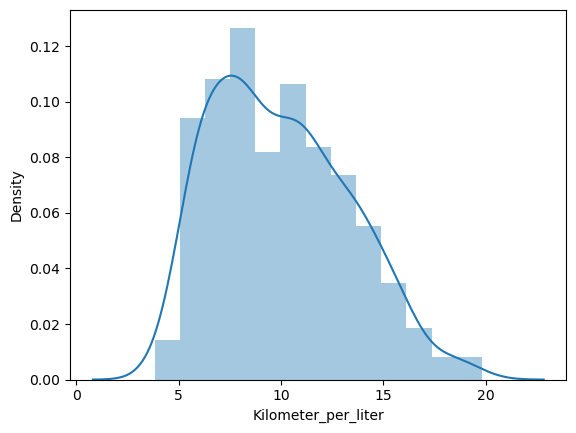

In [10]:
sns.distplot(data.Kilometer_per_liter)

<Axes: xlabel='Kilometer_per_liter'>

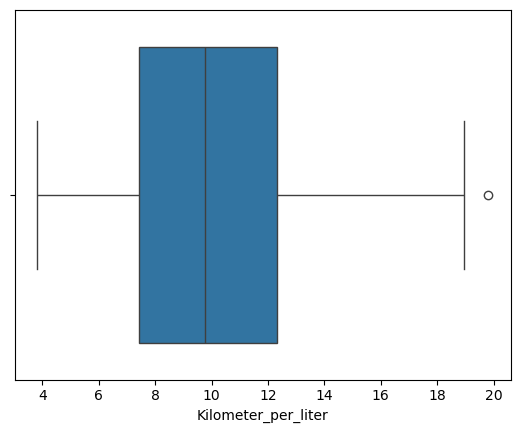

In [11]:
sns.boxplot(x = data.Kilometer_per_liter)

In [12]:
data[data.Kilometer_per_liter == data.Kilometer_per_liter.max()]

,origin,cylinders,displacement,horsepower,weight,acceleration,year,name,Kilometer_per_liter
322,3,4,86.0,65,2110,17.9,1980,mazda glc,19.811697


In [13]:
Q3 = data.Kilometer_per_liter.quantile(0.75)
Q1 = data.Kilometer_per_liter.quantile(0.25)
IQR = Q3 - Q1
LE = Q1 - 1.5*IQR
HE = Q3 + 1.5*IQR

In [14]:
data[(data.Kilometer_per_liter < LE)| (data.Kilometer_per_liter > HE)]


,origin,cylinders,displacement,horsepower,weight,acceleration,year,name,Kilometer_per_liter
322,3,4,86.0,65,2110,17.9,1980,mazda glc,19.811697


In [15]:
data.origin.value_counts()

origin
1    249
3     79
2     70
Name: count, dtype: int64

<Axes: xlabel='origin', ylabel='count'>

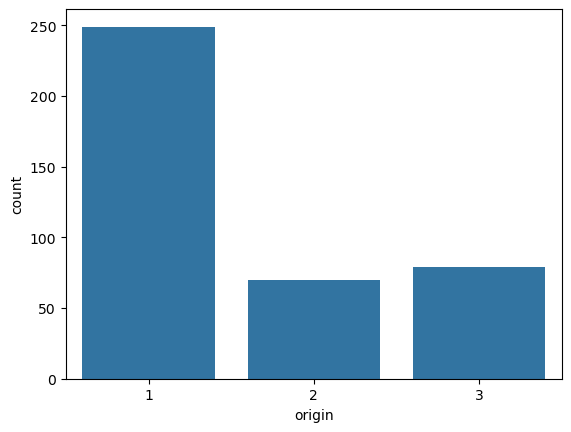

In [16]:
sns.countplot(x=data.origin)

In [17]:
data.groupby("origin")["Kilometer_per_liter"].mean()

origin
1     8.538388
2    11.857865
3    12.945895
Name: Kilometer_per_liter, dtype: float64

In [18]:
#T-test
from scipy.stats import ttest_ind
#Anova Test
import statsmodels.api as sm
from statsmodels.formula.api import ols
#Tukey HSD
from statsmodels.stats.multicomp import pairwise_tukeyhsd
#chi -Square
from scipy.stats import (chi2, chi2_contingency)
import statsmodels.formula.api as smf

In [19]:
data.origin.nunique()

3

In [20]:
model_origin = ols("Kilometer_per_liter ~ origin", data = data).fit()
anova_origin = sm.stats.anova_lm(model_origin)
anova_origin

,df,sum_sq,mean_sq,F,PR(>F)
origin,1.0,1391.68420,1391.684200,184.199639,1.011482e-34
Residual,396.0,2991.90023,7.555304,NaN,NaN


Origin is a good predictor.
if p-value is less thsn level of significance ie- 0.05 then it is good predictor            
when the p-value is smaller then level of signi, then the relationship are significance differed btw origin and km per l

In [21]:
data.columns

Index(['origin', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'name', 'Kilometer_per_liter'],
      dtype='object')

In [22]:
data.cylinders.unique()

array([8, 4, 6, 3, 5], dtype=int64)

In [23]:
data.cylinders.value_counts()

cylinders
4    204
8    103
6     84
3      4
5      3
Name: count, dtype: int64

In [24]:
data[(data.cylinders == 3) | (data.cylinders == 5)]

,origin,cylinders,displacement,horsepower,weight,acceleration,year,name,Kilometer_per_liter
71,3,3,70.0,97,2330,13.5,1972,mazda rx2 coupe,8.077730
111,3,3,70.0,90,2124,13.5,1973,maxda rx3,7.652587
243,3,3,80.0,110,2720,13.5,1977,mazda rx-4,9.140590
274,2,5,131.0,103,2830,15.9,1978,audi 5000,8.630417
297,2,5,183.0,77,3530,20.1,1979,mercedes benz 300d,10.798650
327,2,5,121.0,67,2950,19.9,1980,audi 5000s (diesel),15.475231
334,3,3,70.0,100,2420,12.5,1980,mazda rx-7 gs,10.075906


In [25]:
data.groupby ('cylinders')['Kilometer_per_liter'].mean().sort_values(ascending = False)

cylinders
4    12.451084
5    11.634766
3     8.736703
6     8.496801
8     6.361471
Name: Kilometer_per_liter, dtype: float64

<Axes: xlabel='cylinders'>

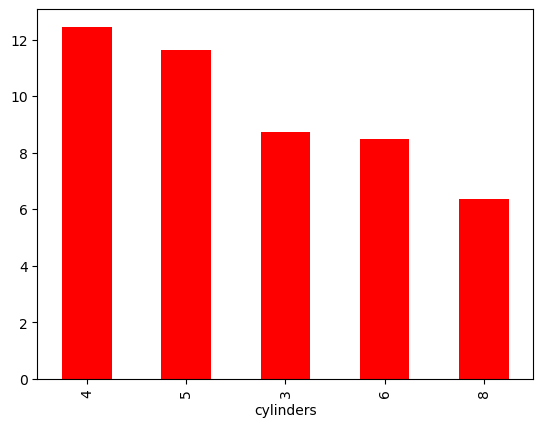

In [26]:
data.groupby ('cylinders')['Kilometer_per_liter'].mean().sort_values(ascending = False).plot(kind = 'bar', color ='red')

Anova test
### Hypothesis Testing
Null hyp: there is no significance diff btw num of cylinders and kms per liter
Alternative hyp: there is a significance diff btw num of cylinders and kmpl

In [27]:
model_cylinder = ols("Kilometer_per_liter ~ cylinders", data = data).fit()
anova_cylinders = sm.stats.anova_lm(model_cylinder)
anova_cylinders

,df,sum_sq,mean_sq,F,PR(>F)
cylinders,1.0,2635.58367,2635.583670,597.077048,4.503992e-81
Residual,396.0,1748.00076,4.414143,NaN,NaN


## Cylinders is a good predictore
P-val is less than lvl of signi hence we reject null hyp and accept alternative hyp
### we conclude that there is signi diff btw cylinders and kmpl

### Displacement

<Axes: xlabel='displacement', ylabel='Density'>

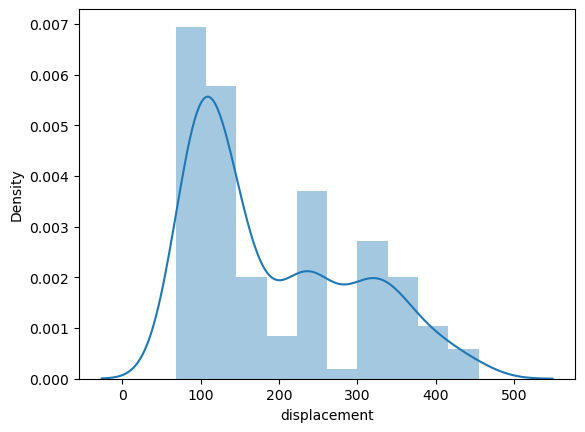

In [28]:
sns.distplot(data.displacement)

<Axes: xlabel='displacement'>

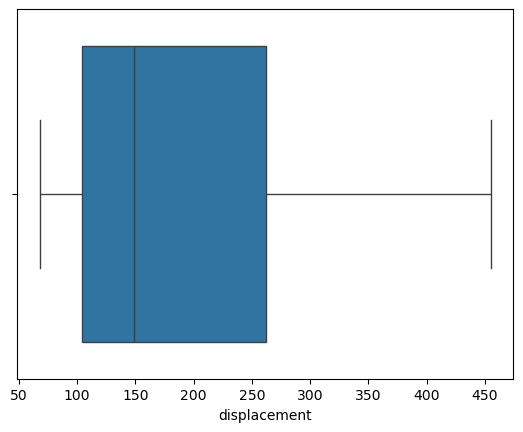

In [29]:
sns.boxplot(x = data.displacement)

<Axes: xlabel='displacement', ylabel='Kilometer_per_liter'>

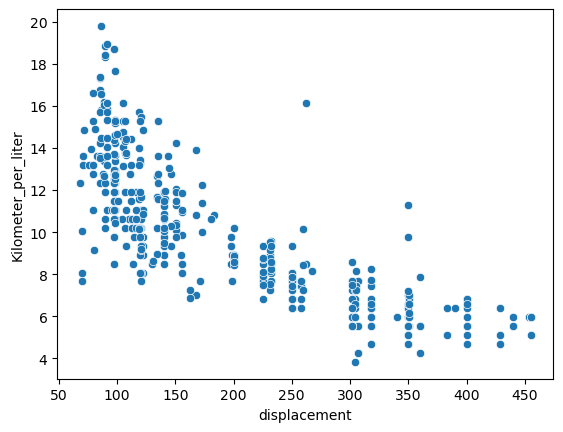

In [30]:
sns.scatterplot(x = "displacement", y = "Kilometer_per_liter", data=data)

In [31]:
data[["displacement","Kilometer_per_liter"]].corr()

,displacement,Kilometer_per_liter
displacement,1.000000,-0.804203
Kilometer_per_liter,-0.804203,1.000000


Displacement and Kilometer_per_literis highly negatively correlated             
       
correlationship should be greater than 0.5 and less than -0.5


<Axes: xlabel='displacement', ylabel='Kilometer_per_liter'>

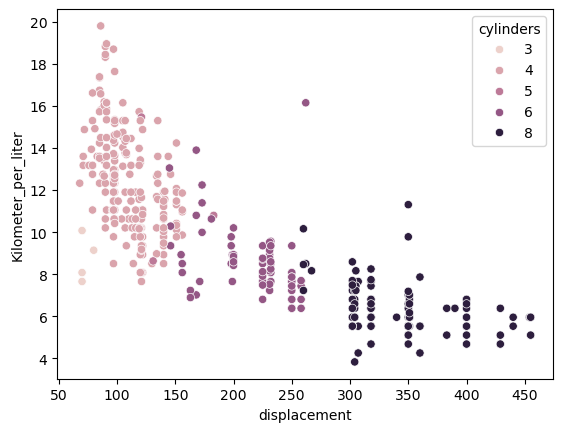

In [32]:
sns.scatterplot(x = "displacement", y= "Kilometer_per_liter", hue='cylinders',data=data)

### 1 caontinous feature      -     1 Continous feature ->Coreelation
### 1 categorical feature with 2 levels     -     1 Continous feature ->T Test
### 1 categorical feature with more than 2 levels     -     1 Continous feature ->Anova Test
### 1 caontinous feature      -     1 Continous feature ->Coreelation
### 1 Categorical feature

<Axes: xlabel='horsepower', ylabel='Kilometer_per_liter'>

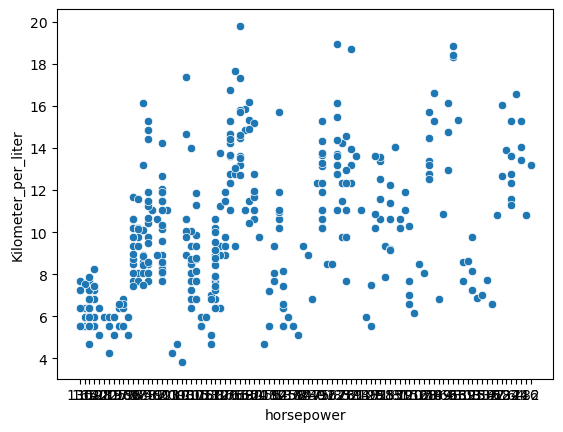

In [33]:
sns.scatterplot(x = "horsepower", y = "Kilometer_per_liter", data=data)

In [51]:
data[["horsepower","Kilometer_per_liter"]].corr()

,horsepower,Kilometer_per_liter
horsepower,1.000000,-0.778427
Kilometer_per_liter,-0.778427,1.000000


### Horsepower is good predictor

In [38]:
data.horsepower.unique()

array(['130', '165', '150', '140', '198', '220', '215', '225', '190',
       '170', '160', '95', '97', '85', '88', '46', '87', '90', '113',
       '200', '210', '193', nan, '100', '105', '175', '153', '180', '110',
       '72', '86', '70', '76', '65', '69', '60', '80', '54', '208', '155',
       '112', '92', '145', '137', '158', '167', '94', '107', '230', '49',
       '75', '91', '122', '67', '83', '78', '52', '61', '93', '148',
       '129', '96', '71', '98', '115', '53', '81', '79', '120', '152',
       '102', '108', '68', '58', '149', '89', '63', '48', '66', '139',
       '103', '125', '133', '138', '135', '142', '77', '62', '132', '84',
       '64', '74', '116', '82'], dtype=object)

In [39]:
data[data.horsepower == '?']

,origin,cylinders,displacement,horsepower,weight,acceleration,year,name,Kilometer_per_liter


In [36]:
data[data.horsepower == '?'].index

Index([32, 126, 330, 336, 354, 374], dtype='int64')

In [41]:
data.horsepower.replace("?", np.nan, inplace = True)

In [ ]:
new_data = data.copy()

In [44]:
data.horsepower.mean()

104.46938775510205

In [43]:
data['horsepower'] = data['horsepower'].astype('float')

<Axes: xlabel='weight', ylabel='Density'>

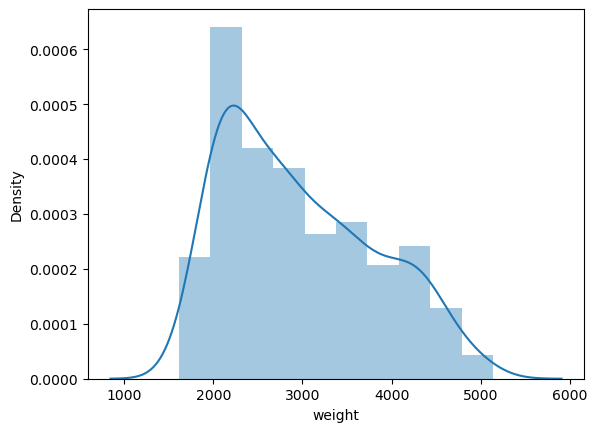

In [45]:
sns.distplot(data.weight)

<Axes: xlabel='weight', ylabel='Kilometer_per_liter'>

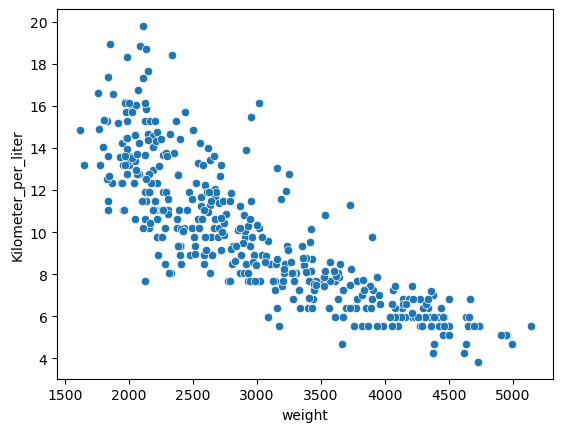

In [46]:
sns.scatterplot(x=data.weight, y=data.Kilometer_per_liter, data=data)

In [47]:
data[["weight", 'Kilometer_per_liter']].corr()

,weight,Kilometer_per_liter
weight,1.000000,-0.831741
Kilometer_per_liter,-0.831741,1.000000


### Weight is also a good predictor

<Axes: xlabel='acceleration', ylabel='Kilometer_per_liter'>

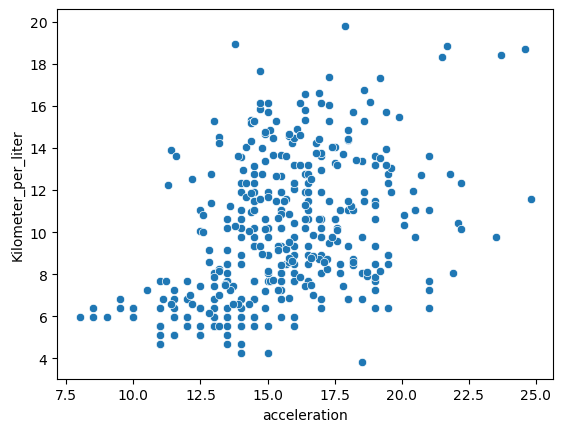

In [48]:
sns.scatterplot(x=data.acceleration, y=data.Kilometer_per_liter, data=data)

In [49]:
data[["acceleration", 'Kilometer_per_liter']].corr()

,acceleration,Kilometer_per_liter
acceleration,1.000000,0.420289
Kilometer_per_liter,0.420289,1.000000


## Acceleration is a bad predictor

In [52]:
data.columns

Index(['origin', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'name', 'Kilometer_per_liter'],
      dtype='object')

<Axes: xlabel='year', ylabel='Kilometer_per_liter'>

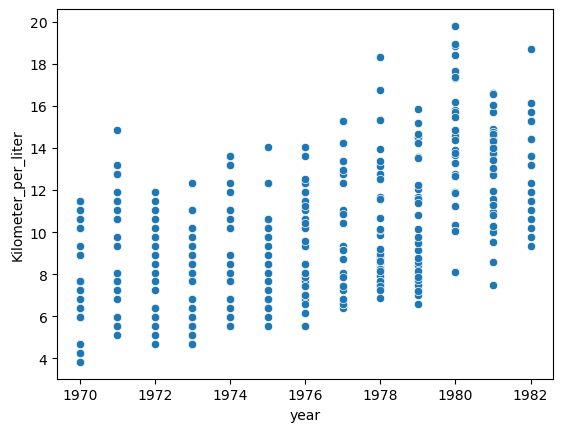

In [53]:
sns.scatterplot(x=data.year, y=data.Kilometer_per_liter, data=data)

In [54]:
data[["year", 'Kilometer_per_liter']].corr()

,year,Kilometer_per_liter
year,1.000000,0.579267
Kilometer_per_liter,0.579267,1.000000


### it is greater than lvl of sign ie-0.5
## it is slightly a good predictor

In [55]:
data.drop('name', axis=1, inplace=True)

In [56]:
data

,origin,cylinders,displacement,horsepower,weight,acceleration,year,Kilometer_per_liter
0,1,8,307.0,130.0,3504,12.0,1970,7.652587
1,1,8,350.0,165.0,3693,11.5,1970,6.377156
2,1,8,318.0,150.0,3436,11.0,1970,7.652587
3,1,8,304.0,150.0,3433,12.0,1970,6.802299
4,1,8,302.0,140.0,3449,10.5,1970,7.227443
...,...,...,...,...,...,...,...,...
393,1,4,140.0,86.0,2790,15.6,1982,11.478880
394,2,4,97.0,52.0,2130,24.6,1982,18.706323
395,1,4,135.0,84.0,2295,11.6,1982,13.604599
396,1,4,120.0,79.0,2625,18.6,1982,11.904024


In [68]:
X = data.drop("Kilometer_per_liter", axis = 1)
y = data.Kilometer_per_liter

## Start to work with model

In [69]:
from sklearn.model_selection import train_test_split

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,train_size=0.8, random_state = 0)

In [71]:
data.shape[0]*0.8

318.40000000000003

In [72]:
from sklearn.linear_model import LinearRegression

In [73]:
model1=LinearRegression()
model1.fit(X_train,y_train)

LinearRegression()

In [67]:
data.horsepower.fillna(data.horsepower.median(),inplace =True)

In [75]:
y_train_pred= model1.predict(X_train)

In [76]:
y_train_pred

array([ 5.2509015 , 11.78709965, 13.25263115, 12.38725204, 13.4632941 ,
       14.31369669, 12.60682278,  9.31699501, 11.39392697, 13.50057081,
       10.77129269,  4.14420071, 11.09206839, 13.58341123, 11.64674211,
        8.61684139,  8.45193638, 10.71005798, 10.1495411 ,  4.97689134,
       10.36291731, 14.18808351, 10.77513896, 11.09159868, 15.11930343,
       11.64471734, 10.8069871 ,  6.39157698,  6.46585624,  9.5361046 ,
        9.3026239 , 12.21148281,  7.39240878, 14.34576555,  9.65588844,
       10.37889936, 12.89913247,  5.1347195 ,  7.37546869, 14.31810626,
        6.70144611, 12.9990971 ,  5.58789305,  9.63069905,  8.30822049,
        9.75490256, 14.00233985, 13.67869815, 11.89934926, 10.80921471,
        6.22652374, 11.91792365,  9.21325336,  8.85862853, 14.8511129 ,
       14.99210281, 14.41617254,  8.87947312, 12.87397814,  8.81822585,
        9.78901   , 10.70567213, 11.41135162,  3.99531633, 14.80274009,
       11.79122609,  5.28985659,  4.91258804, 11.37877026,  9.07

In [77]:
y_test_pred = model1.predict(X_test)

In [78]:
model1.coef_

array([ 0.66828877, -0.16923856,  0.00911166, -0.00851176, -0.00273882,
        0.08244457,  0.31690098])

In [79]:
model1.intercept_

-610.4009347017752

In [80]:
from sklearn.metrics import r2_score
r2_score(y_train, y_train_pred)

0.818895592343263

In [81]:
r2_score(y_test, y_test_pred)

0.8194884044248881

In [82]:
y_test

65      5.952012
132    10.628593
74      5.526868
78      8.928018
37      7.652587
         ...    
269    13.136941
235    11.053736
145    13.604599
196    10.416021
124     4.676581
Name: Kilometer_per_liter, Length: 80, dtype: float64

In [83]:
y_test_pred

array([ 5.5012617 , 10.22966366,  4.96087123,  8.98902226,  7.39913426,
       12.67382616, 14.14834591, 10.04129888,  6.05879697, 11.24830606,
       14.10183   , 14.44367221,  9.11279735, 11.37576648,  6.88076002,
       12.89180558, 12.22430094, 12.2912753 ,  7.43582416, 13.02582869,
        6.6145381 , 10.50775511, 11.49632209,  8.49910287, 12.4383039 ,
       12.00896086, 13.00903379, 12.88414354, 12.41777872,  7.76557943,
        8.8230756 , 13.26250592,  9.12813216, 13.67694946, 10.15081779,
       10.92295769,  9.08641196,  7.21741017, 13.49432919,  3.76812558,
        4.28965965,  5.82666654, 11.08302982, 12.74941106, 13.36669544,
        9.53950353,  9.79787128,  5.76829197,  9.38296797, 11.87234631,
       13.30858548, 11.29058582,  6.5370659 , 10.56523804,  6.31717258,
        3.55489396,  8.27888673, 11.13507482, 12.78400649,  6.18792882,
        9.00504984, 10.54569645,  9.35838619,  8.06115966,  4.52464701,
        5.08964765,  4.3671761 ,  8.361073  , 10.21280481,  4.27

In [89]:
final_df = pd.DataFrame()
final_df["Actual"]=y_test
final_df["Predicted"]=y_test_pred
final_df

,Actual,Predicted
65,5.952012,5.501262
132,10.628593,10.229664
74,5.526868,4.960871
78,8.928018,8.989022
37,7.652587,7.399134
...,...,...
269,13.136941,11.826761
235,11.053736,12.982730
145,13.604599,12.807155
196,10.416021,12.064194


## Plotting


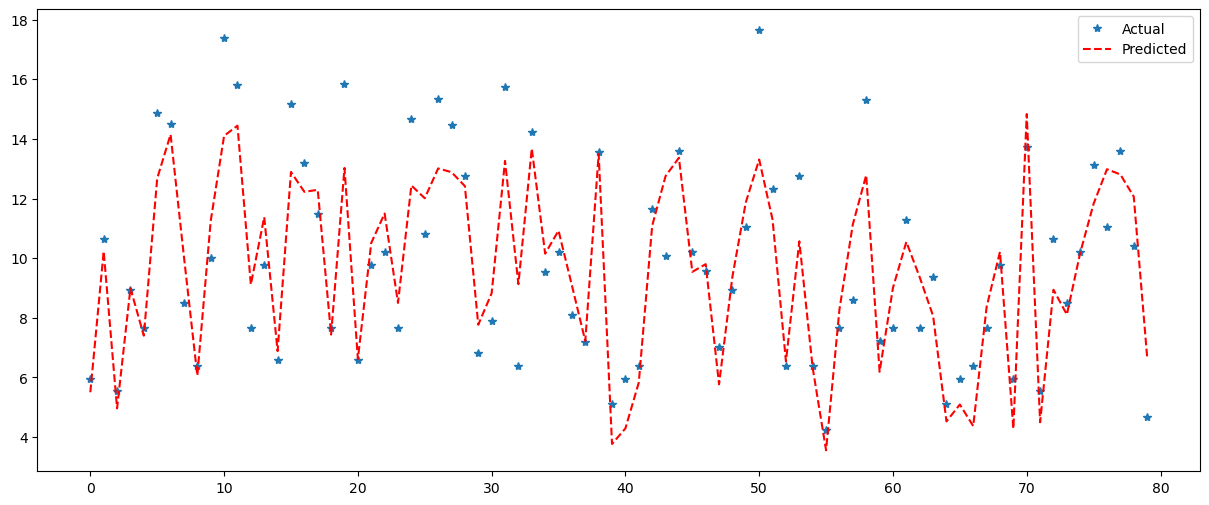

In [101]:
plt.figure(figsize=(15,6))
obsno = list(range(y_test.shape[0]))
plt.plot(obsno, final_df.Actual, "*", label="Actual")
plt.plot(obsno, final_df.Predicted, "r--", label="Predicted")
plt.legend()

In [102]:
y_test.shape[0]

80

In [104]:
model1.predict([[3,6,85,70,5500,17,1990]])

array([7.73816135])

### creating a function

In [107]:
def predict_mpg():
    origin = int(input("Enter the Origin:"))
    cylinders = int(input("Enter no of Cylinders:"))
    displacement = int(input("Enter the displacement:"))
    horsepower = int(input("Enter the horsepower:"))
    weight = int(input("Enter the weight:"))
    acceleration = int(input("Enter the acceleration:"))
    year = int(input("Enter the manufacturing year:"))

    new_df = pd.DataFrame({
        "origin":[origin],
        "cylinders":[cylinders],
        "displacement":[displacement],
        "horsepower":[horsepower],
        "weight":[weight],
        "acceleration":[acceleration],
        "year":[year]
    })
    prediction = model1.predict(new_df)
    print("The Mileage of the vehicle is = ", prediction) 



In [108]:
predict_mpg()

Enter the Origin: 1
Enter no of Cylinders: 5
Enter the displacement: 250
Enter the horsepower: 100
Enter the weight: 2600
Enter the acceleration: 15
Enter the manufacturing year: 1980


The Mileage of the vehicle is =  [12.42757893]
